In [1]:
import pymongo as pm
import pandas as pd
from datetime import datetime, timezone
import matplotlib.pyplot as plt
import numpy as np

client = pm.MongoClient(
 'bigdatadb.polito.it',
 ssl=True,
 authSource='carsharing',
 username='ictts',
 password='Ict4SM22!',
 tlsAllowInvalidCertificates=True
)

In [2]:
db= client['carsharing']
pb_coll = db['PermanentBookings']
ap_coll = db['ActiveParkings']
ab_coll = db['ActiveParkings']
pp_coll = db['PermanentParkings']

In [3]:
start = int(datetime(2017, 11, 1, tzinfo=timezone.utc).timestamp())
end   = int(datetime(2018, 2, 1, tzinfo=timezone.utc).timestamp())
    
cities = ["Torino","Columbus","Frankfurt"]

In [4]:
def load_wtime(coll, city):
    pipe = [
        {"$match": {"city": city, "init_time": {"$gte": start, "$lt": end}}},
        {"$project": {"_id": 0, 
                      "init_time": 1,
                      "duration": {"$subtract": ["$final_time", "$init_time"]},
                      "day":      {"$dateToString": {"date": "$init_date", "format": "%Y-%m-%d"}},
                        "week":     {"$isoWeek": "$init_date"},
                        "iso_year": {"$isoWeekYear": "$init_date"},
                        "dow":      {"$isoDayOfWeek": "$init_date"},
                        "hour":     {"$hour": "$init_date"},}}           
    ]
        
    df = pd.DataFrame(db[coll].aggregate(pipe, allowDiskUse=True))
    df["duration_min"] = df["duration"]/60
    return df

In [5]:
bookings = {c: load_wtime("PermanentBookings", c) for c in cities}
parkings = {c: load_wtime("PermanentParkings", c) for c in cities}

In [ ]:
def best_zone(x, q=0.9, log=True):
    """
    Zone la plus dense : le plus petit intervalle [a, b] qui contient une fraction q
    des échantillons (sur la ECDF : F(b) - F(a) = q).
    log=True : la largeur est mesurée en log(durée), adapté aux durées très étalées
               -> on enlève à la fois les durées très courtes et la longue traîne.
               Les durées <= 0 (invalides) sont retirées avant le calcul.
    """
    x = np.sort(np.asarray(x, dtype=float))
    if log:
        x = x[x > 0]
    t = np.log(x) if log else x
    n = len(x)
    k = int(np.ceil(q * n))                 # nb de points à garder
    widths = t[k - 1:] - t[:n - k + 1]      # largeur de chaque fenêtre de k points consécutifs
    i = np.argmin(widths)
    return x[i], x[i + k - 1]


def keep_best_zone(df, q=0.9, col="duration_min", log=True):
    """Garde uniquement les lignes dont la durée est dans la zone la plus dense."""
    a, b = best_zone(df[col].values, q, log)
    return df[df[col].between(a, b)].copy(), (a, b)


Q = 0.90   # fraction de la ECDF à conserver

raw = {"bookings": bookings, "parkings": parkings}
filtered = {kind: {} for kind in raw}
zones = {}
for kind, data in raw.items():
    for c in cities:
        filtered[kind][c], zones[(kind, c)] = keep_best_zone(data[c], Q)
        a, b = zones[(kind, c)]
        n0, n1 = len(data[c]), len(filtered[kind][c])

bookings_f = filtered["bookings"]
parkings_f = filtered["parkings"]

In [ ]:
def plot_cdf(data_dict, title, ax):
    for city, df in data_dict.items():
        x = np.sort(df["duration_min"].values)
        x = x[x > 0]                                  # nécessaire pour l'axe log
        y = np.arange(1, len(x)+1) / len(x)
        ax.plot(x, y, label=city)
    ax.set_xscale("log")
    ax.set_xlabel("Durée (minutes, échelle log)")
    ax.set_ylabel("CDF")
    ax.set_title(title)
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()


fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
plot_cdf(bookings, "Durée des bookings", axes[0])
plot_cdf(parkings, "Durée des parkings", axes[1])
plt.tight_layout(); plt.show()

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
plot_cdf(bookings_f, "Durée des bookings", axes[0])
plot_cdf(parkings_f, "Durée des parkings", axes[1])
plt.tight_layout(); plt.show()

## Q4 – Utilisation du système et CDF après filtrage
On réutilise `raw`, `filtered` et `zones` calculés plus haut (zone la plus dense, 90 % de la ECDF).

In [9]:
# Occupation horaire : nombre de voitures réservées / garées dans chaque créneau d'1h.
# Même définition que la V1 de TP1.ipynb (un événement compte dans chaque heure qu'il touche),
# mais vectorisée (bincount + cumsum) : instantané au lieu d'une boucle sur ~2200 heures.

TZ = {"Torino": "Europe/Rome", "Columbus": "America/New_York", "Frankfurt": "Europe/Berlin"}
N_HOURS = (end - start) // 3600

def hourly_occupancy(df):
    d = df[df["duration"] > 0]
    t0 = d["init_time"].to_numpy(dtype=np.int64)
    t1 = t0 + d["duration"].to_numpy(dtype=np.int64)
    s = np.clip((t0 - start) // 3600, 0, N_HOURS)        # premier créneau touché
    e = np.clip(-((start - t1) // 3600), 0, N_HOURS)     # créneau de fin, exclu (= arrondi supérieur)
    diff = np.bincount(s, minlength=N_HOURS + 1) - np.bincount(e, minlength=N_HOURS + 1)
    idx = pd.date_range(pd.Timestamp(start, unit="s", tz="UTC"), periods=N_HOURS, freq="h")
    return pd.Series(np.cumsum(diff)[:N_HOURS], index=idx)

def hour_of_day_profile(occ, city):
    """Moyenne de l'occupation pour chaque heure locale (0-23)."""
    local = occ.tz_convert(TZ[city])
    return local.groupby(local.index.hour).mean()

occ_raw = {k: {c: hourly_occupancy(raw[k][c]) for c in cities} for k in raw}
occ_f   = {k: {c: hourly_occupancy(filtered[k][c]) for c in cities} for k in raw}

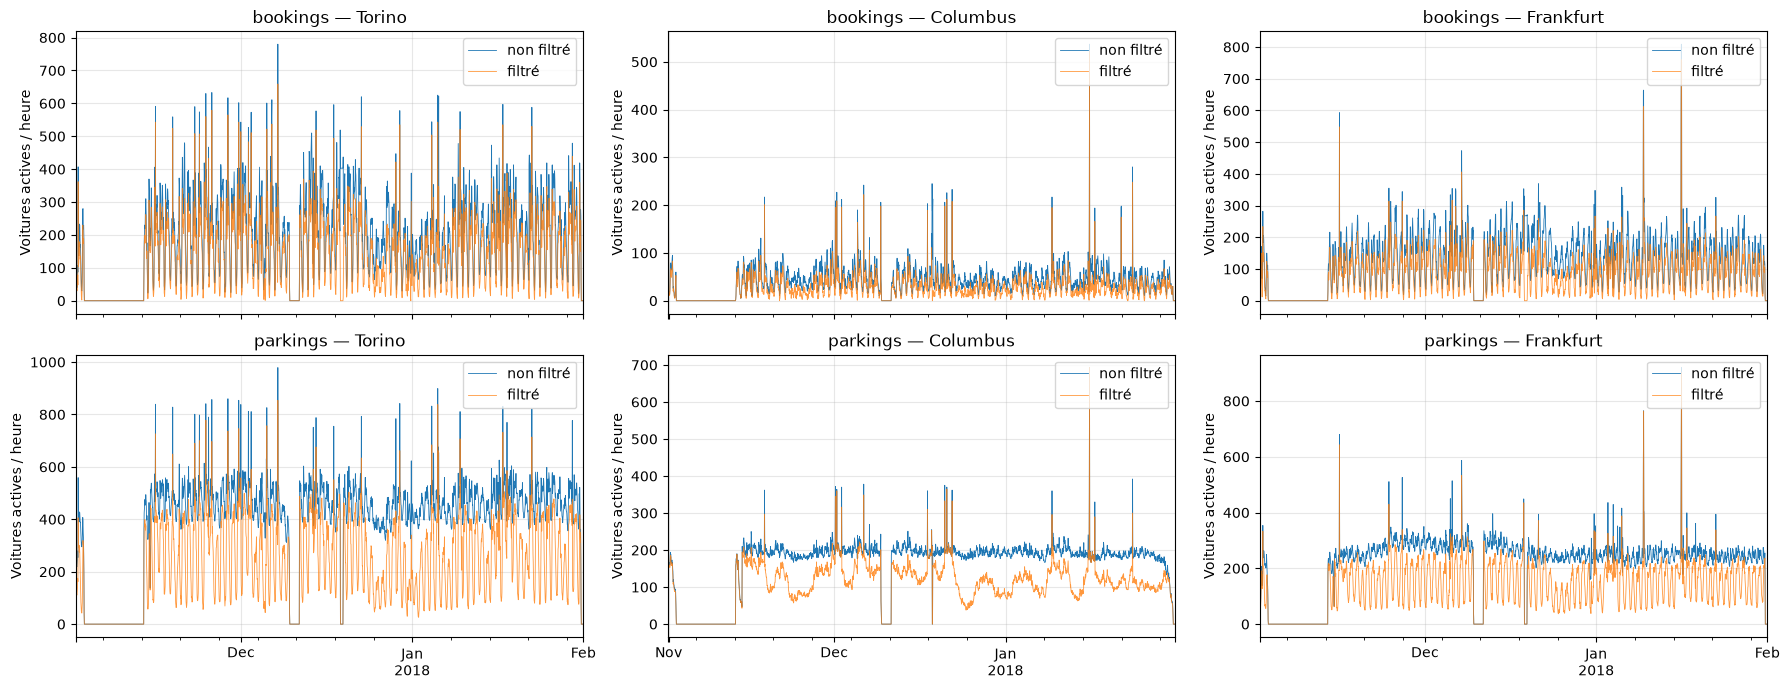

In [11]:
# Série temporelle heure par heure sur toute la période : non filtré vs filtré
fig, axes = plt.subplots(2, 3, figsize=(18, 7), sharex="col")
for r, kind in enumerate(raw):
    for j, c in enumerate(cities):
        ax = axes[r, j]
        occ_raw[kind][c].tz_convert(TZ[c]).plot(ax=ax, lw=0.6, label="non filtré")
        occ_f[kind][c].tz_convert(TZ[c]).plot(ax=ax, lw=0.6, alpha=0.8, label="filtré")
        ax.set_title(f"{kind} — {c}")
        ax.set_ylabel("Voitures actives / heure")
        ax.grid(alpha=0.3)
        ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

In [ ]:
# Profil moyen par heure de la journée (heure locale) : non filtré vs filtré
fig, axes = plt.subplots(2, 3, figsize=(18, 7))
for r, kind in enumerate(raw):
    for j, c in enumerate(cities):
        ax = axes[r, j]
        p_raw = hour_of_day_profile(occ_raw[kind][c], c)
        p_f   = hour_of_day_profile(occ_f[kind][c], c)
        ax.bar(p_raw.index - 0.2, p_raw.values, width=0.4, label="non filtré")
        ax.bar(p_f.index + 0.2, p_f.values, width=0.4, label="filtré")
        ax.set_title(f"{kind} — {c}")
        ax.set_xlabel("Heure locale")
        ax.set_ylabel("Moyenne de voitures actives")
        ax.set_xticks(range(24))
        ax.grid(axis="y", alpha=0.3)
        ax.legend()
plt.tight_layout(); plt.show()

In [ ]:
# Part des événements retirés vs part de l'occupation retirée
# (un événement long compte dans beaucoup d'heures -> il pèse plus que 1 dans l'occupation)
rows = []
for kind in raw:
    for c in cities:
        n0, n1 = len(raw[kind][c]), len(filtered[kind][c])
        o0, o1 = occ_raw[kind][c].mean(), occ_f[kind][c].mean()
        rows.append({"type": kind, "ville": c,
                     "événements retirés": f"{1 - n1 / n0:.1%}",
                     "occupation moyenne brute": round(o0, 1),
                     "occupation moyenne filtrée": round(o1, 1),
                     "occupation retirée": f"{1 - o1 / o0:.1%}"})
pd.DataFrame(rows)

In [ ]:
# CDF brute (trait plein) vs filtrée (pointillés), une figure par ville ; zone gardée en gris
fig, axes = plt.subplots(2, 3, figsize=(18, 8), sharey=True)
for r, kind in enumerate(raw):
    for j, c in enumerate(cities):
        ax = axes[r, j]
        for df, style, lab in [(raw[kind][c], "-", "non filtré"), (filtered[kind][c], "--", "filtré")]:
            x = np.sort(df["duration_min"].to_numpy())
            x = x[x > 0]
            ax.plot(x, np.arange(1, len(x) + 1) / len(x), style,
                    label=f"{lab} (médiane {np.median(x):.1f} min)")
        ax.axvspan(*zones[(kind, c)], color="grey", alpha=0.15)
        ax.set_xscale("log")
        ax.set_title(f"{kind} — {c}")
        ax.set_xlabel("Durée (minutes, échelle log)")
        ax.set_ylabel("CDF")
        ax.grid(True, which="both", alpha=0.3)
        ax.legend(fontsize=8)
plt.tight_layout(); plt.show()